ANFIS Eğitimi Başlıyor...
Epoch [300/1500] | Eğitim MSE Kaybı: 0.01561
Epoch [600/1500] | Eğitim MSE Kaybı: 0.01537
Epoch [900/1500] | Eğitim MSE Kaybı: 0.01536
Epoch [1200/1500] | Eğitim MSE Kaybı: 0.01529
Epoch [1500/1500] | Eğitim MSE Kaybı: 0.01522

--- ANFIS (Reproduction Baseline) Başarısı ---
MSE: 0.01024 | MAE: 0.05684 | R2: -1.67120


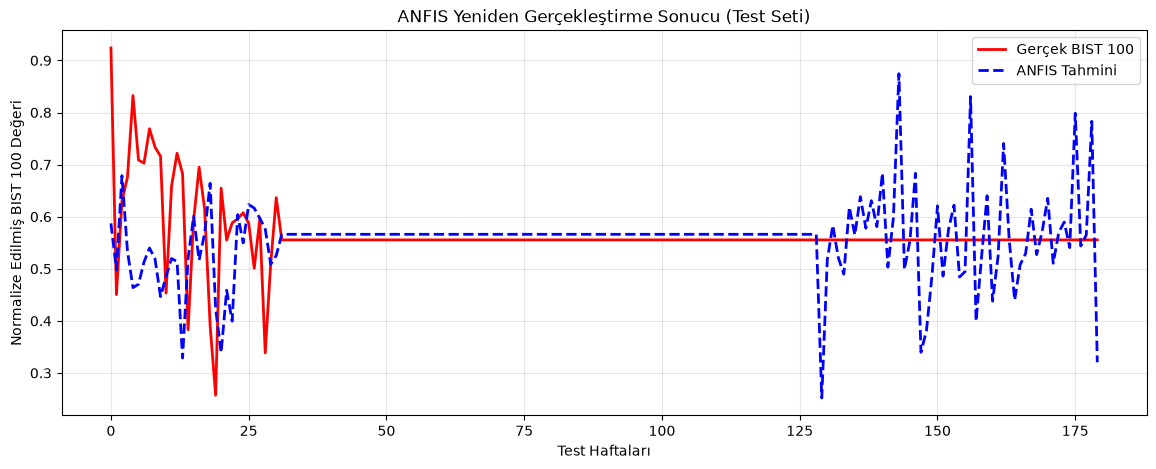

In [1]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Uyarıları gizle
import warnings
warnings.filterwarnings('ignore')

data_dir = "../data"

# 1. Verileri Yükle
train_df = pd.read_csv(os.path.join(data_dir, 'processed_train.csv'), index_col='Date', parse_dates=True)
test_df = pd.read_csv(os.path.join(data_dir, 'processed_test.csv'), index_col='Date', parse_dates=True)

X_train = train_df[['GOLD_TL', 'VIX', 'BOND_2Y']].values
y_train = train_df['BIST100'].values
X_test = test_df[['GOLD_TL', 'VIX', 'BOND_2Y']].values
y_test = test_df['BIST100'].values

# PyTorch Tensörlerine Çevir
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

# 2. ANFIS MİMARİSİ (Takagi-Sugeno)
class ANFIS(nn.Module):
    def __init__(self, num_inputs, num_rules):
        super(ANFIS, self).__init__()
        self.num_inputs = num_inputs
        self.num_rules = num_rules
        
        # Katman 1: Üyelik Fonksiyonları (Gaussian MF) -> Mu ve Sigma parametreleri
        self.mu = nn.Parameter(torch.rand(num_rules, num_inputs))
        self.sigma = nn.Parameter(torch.rand(num_rules, num_inputs) + 0.1) 
        
        # Katman 4: Çıkarım (Consequent) Parametreleri -> Doğrusal denklem ağırlıkları
        self.consequent_weights = nn.Parameter(torch.rand(num_rules, num_inputs))
        self.consequent_bias = nn.Parameter(torch.rand(num_rules, 1))

    def forward(self, x):
        batch_size = x.shape[0]
        
        # Katman 1 (Fuzzification): Gaussian Üyelik Değerlerinin Hesaplanması
        x_expanded = x.unsqueeze(1).expand(-1, self.num_rules, -1)
        mu_expanded = self.mu.unsqueeze(0).expand(batch_size, -1, -1)
        sigma_expanded = self.sigma.unsqueeze(0).expand(batch_size, -1, -1)
        
        fuzzy_vals = torch.exp(-0.5 * ((x_expanded - mu_expanded) / sigma_expanded)**2)
        
        # Katman 2 (Fuzzy AND): Kural Ateşleme Güçleri (Çarpım T-norm)
        firing_strengths = torch.prod(fuzzy_vals, dim=2)
        
        # Katman 3 (Normalization): Ateşleme Güçlerinin Normalize Edilmesi
        normalized_firing = firing_strengths / (torch.sum(firing_strengths, dim=1, keepdim=True) + 1e-8)
        
        # Katman 4 (Inference): Takagi-Sugeno Doğrusal Çıktıları
        consequent_outputs = torch.matmul(x, self.consequent_weights.T) + self.consequent_bias.T
        
        # Katman 5 (Defuzzification): Ağırlıklı Toplam Sonuç
        output = torch.sum(normalized_firing * consequent_outputs, dim=1, keepdim=True)
        return output

# Model Kurulumu (3 Girdi, Makaledeki gibi 8 Kural)
torch.manual_seed(42)
model = ANFIS(num_inputs=3, num_rules=8)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# 3. Modelin Eğitilmesi
epochs = 1500
print("ANFIS Eğitimi Başlıyor...")
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    
    if (epoch+1) % 300 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Eğitim MSE Kaybı: {loss.item():.5f}")

# 4. Test ve Değerlendirme
model.eval()
with torch.no_grad():
    anfis_preds_t = model(X_test_t)
anfis_preds = anfis_preds_t.numpy()

mse = mean_squared_error(y_test, anfis_preds)
mae = mean_absolute_error(y_test, anfis_preds)
r2 = r2_score(y_test, anfis_preds)

print("\n--- ANFIS (Reproduction Baseline) Başarısı ---")
print(f"MSE: {mse:.5f} | MAE: {mae:.5f} | R2: {r2:.5f}")

# 5. Grafiksel Sonuç
plt.figure(figsize=(14, 5))
plt.plot(y_test, label="Gerçek BIST 100", color="red", linewidth=2)
plt.plot(anfis_preds, label="ANFIS Tahmini", linestyle="--", color="blue", linewidth=2)
plt.title("ANFIS Yeniden Gerçekleştirme Sonucu (Test Seti)")
plt.xlabel("Test Haftaları")
plt.ylabel("Normalize Edilmiş BIST 100 Değeri")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../results/figures/anfis_baseline.png', dpi=300, bbox_inches='tight')
plt.show()